# 01 - EDA y limpieza: World Happiness Report 2015-2019

Notebook de exploración, integración y limpieza de los datos consumidos desde Apache Kafka (tópico `etl.records`).

## Objetivo
Construir un dataset único y consistente (una fila por país-año) a partir de cinco esquemas anuales distintos, documentando cuántos datos llegan, cuántos se procesan y cuántos se limpian en cada etapa.

## Entradas y salidas
| Tipo | Ruta | Descripción |
|---|---|---|
| Entrada | `data/raw_records.csv` | Estado en memoria volcado por `src/extract.py` (un registro por mensaje de Kafka) |
| Salida | `data/clean_records.csv` | Dataset limpio en formato largo, entrada del notebook de modelado |
| Salida | `reports/figures/*.png` | Gráficas del EDA |
| Salida | `reports/tables/*.csv` | Embudo de datos, registro de limpieza y mapa de columnas |

## Etapas
1. Extracción: verificación de lo recibido desde Kafka.
2. Perfilado: esquema, columnas comunes y únicas, nulos por año.
3. Integración: mapa de nombres y unión en formato largo.
4. Calidad: formatos, nombres de país, duplicados, región, nulos, ceros, atípicos y cambios de escala entre años.
5. Exploración: estadísticas descriptivas y relaciones entre variables.
6. Embudo de datos: llegan, se procesan, se limpian.
7. Hallazgos, decisiones y limitaciones.

Convención: cada etapa del flujo registra sus conteos con la función `registrar()`, y al final se consolidan en una única tabla (`embudo`).

In [9]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RUTA_RAW = "../data/raw_records.csv"
RUTA_CLEAN = "../data/clean_records.csv"
DIR_FIG = "../reports/figures"
DIR_TAB = "../reports/tables"
os.makedirs(DIR_FIG, exist_ok=True)
os.makedirs(DIR_TAB, exist_ok=True)

# Estilo monocromático (escala de grises)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "black",
    "axes.grid": True, "grid.color": "0.85", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 9,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

# Registro de las etapas del flujo (se consolida al final como "embudo")
embudo = []
def registrar(etapa, filas, columnas=None, paises=None, nota=""):
    embudo.append({"etapa": etapa, "filas": filas, "columnas": columnas,
                   "paises_unicos": paises, "nota": nota})

YEARS = [2015, 2016, 2017, 2018, 2019]
META = ["source_file", "year", "record_id", "_partition", "_offset"]
print("Configuración lista.")

Configuración lista.


## 1. Extracción: datos que llegan

Se contrasta el número de mensajes disponibles en el tópico (offsets de cada partición) con el número de registros almacenados en `raw_records.csv`.

La consulta a Kafka es opcional: si no hay conexión o credenciales, se usa el valor registrado por `src/extract.py` en su ejecución (782 mensajes esperados, 782 consumidos) y la nota de la tabla lo indica. La consulta solo lee offsets: no se suscribe al grupo ni hace commit.

In [13]:
MENSAJES_REGISTRADOS_EN_EXTRACT = 782   # valor impreso por src.extract ("Mensajes esperados en el tópico")

def mensajes_en_topico():
    """Suma (high - low) de los offsets de todas las particiones. None si no hay conexión."""
    try:
        sys.path.insert(0, os.path.abspath(".."))
        from confluent_kafka import Consumer, TopicPartition
        from src.config import kafka_conf, TOPIC
        consumer = Consumer(kafka_conf())
        try:
            md_ = consumer.list_topics(TOPIC, timeout=15)
            total = 0
            for pid in md_.topics[TOPIC].partitions:
                low, high = consumer.get_watermark_offsets(TopicPartition(TOPIC, pid), timeout=10)
                total += high - low
            return total
        finally:
            consumer.close()
    except Exception as e:
        print("Kafka no consultado en esta ejecución:", type(e).__name__)
        return None

total_topico = mensajes_en_topico()
fuente_topico = "consulta en vivo a Kafka"
if total_topico is None:
    total_topico = MENSAJES_REGISTRADOS_EN_EXTRACT
    fuente_topico = "valor registrado por src.extract (sin consulta en vivo)"

df_raw = pd.read_csv(RUTA_RAW)
cols_datos = [c for c in df_raw.columns if c not in META]
nombres_crudos = pd.concat([df_raw["Country"], df_raw["Country or region"]]).dropna().str.strip()

registrar("1. Mensajes disponibles en el tópico", total_topico, None, None, fuente_topico)
registrar("2. Mensajes consumidos y almacenados", len(df_raw), len(df_raw.columns),
          nombres_crudos.nunique(), "raw_records.csv (incluye 5 columnas de metadatos)")

print("Mensajes en el tópico:", total_topico, f"({fuente_topico})")
print("Registros en raw_records.csv:", len(df_raw))
print("Columnas totales:", df_raw.shape[1], "| de metadatos:", len(META), "| de datos:", len(cols_datos))
print("Nombres de país distintos (crudos):", nombres_crudos.nunique())

Mensajes en el tópico: 782 (consulta en vivo a Kafka)
Registros en raw_records.csv: 782
Columnas totales: 35 | de metadatos: 5 | de datos: 30
Nombres de país distintos (crudos): 170


In [14]:
# Validaciones de integridad del estado en memoria
dup_id = int(df_raw["record_id"].duplicated().sum())
fuera_rango = int((~df_raw["year"].isin(YEARS)).sum())
archivo_inconsistente = int((df_raw["source_file"] != df_raw["year"].astype(str) + ".csv").sum())

print("record_id duplicados:", dup_id)
print("Registros con año fuera de 2015-2019:", fuera_rango)
print("Registros cuyo source_file no coincide con el año:", archivo_inconsistente)
print("Diferencia tópico - consumidos:", total_topico - len(df_raw))

assert dup_id == 0 and fuera_rango == 0 and archivo_inconsistente == 0

registrar("3. Sin duplicados por record_id", len(df_raw) - dup_id, len(df_raw.columns),
          nombres_crudos.nunique(), "duplicados detectados: %d" % dup_id)

print("\nRegistros y partición por año:")
display(pd.crosstab(df_raw["year"], df_raw["_partition"], margins=True))

record_id duplicados: 0
Registros con año fuera de 2015-2019: 0
Registros cuyo source_file no coincide con el año: 0
Diferencia tópico - consumidos: 0

Registros y partición por año:


_partition,0,1,2,All
year,,,,
2015,37,61,60,158
2016,45,60,52,157
2017,49,48,58,155
2018,48,51,57,156
2019,49,49,58,156
All,228,269,285,782


## 2. Perfilado de esquemas por año

El DataFrame apilado de Kafka tiene 35 columnas porque cada año usa nombres distintos y las columnas de otros años quedan vacías. Esos vacíos son un efecto de apilar esquemas, no datos faltantes. Para ver el esquema original de cada archivo se conservan, por año, solo las columnas con al menos un valor.

In [15]:
esquemas = {}
for year, g in df_raw.groupby("year"):
    esquemas[year] = [c for c in g.columns if c not in META and g[c].notna().any()]

sets = {y: set(c) for y, c in esquemas.items()}
todas = sorted(set.union(*sets.values()))
comunes = set.intersection(*sets.values())

resumen_esq = pd.DataFrame({
    "filas": df_raw.groupby("year").size(),
    "columnas_con_datos": {y: len(c) for y, c in esquemas.items()},
})
display(resumen_esq)

print("Columnas originales distintas (unión de los 5 años):", len(todas))
print("Comunes a los 5 años por nombre exacto:", sorted(comunes))
for y, s in sets.items():
    otros = set.union(*[v for k, v in sets.items() if k != y])
    print(f"Solo en {y}:", sorted(s - otros))

print("\nNulos reales (dentro del esquema propio de cada año):")
nulos_reales = {}
for year, g in df_raw.groupby("year"):
    n = g[esquemas[year]].isna().sum()
    n = n[n > 0]
    nulos_reales[year] = n.to_dict()
    print(f"  {year}:", n.to_dict() if len(n) else "ninguno")

,filas,columnas_con_datos
2015,158,12
2016,157,13
2017,155,12
2018,156,9
2019,156,9


Columnas originales distintas (unión de los 5 años): 30
Comunes a los 5 años por nombre exacto: ['Generosity']
Solo en 2015: ['Standard Error']
Solo en 2016: ['Lower Confidence Interval', 'Upper Confidence Interval']
Solo en 2017: ['Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']
Solo en 2018: []
Solo en 2019: []

Nulos reales (dentro del esquema propio de cada año):
  2015: ninguno
  2016: ninguno
  2017: ninguno
  2018: {'Perceptions of corruption': 1}
  2019: ninguno


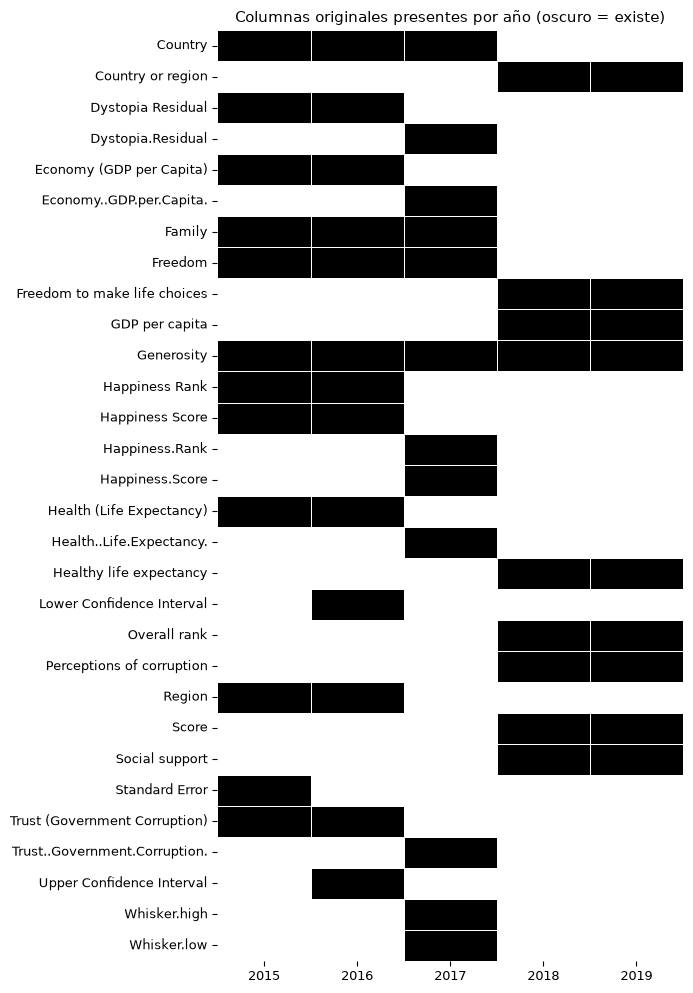

In [16]:
# Gráfica 1: presencia de columnas originales por año
pres = pd.DataFrame({y: {c: int(c in s) for c in todas} for y, s in sets.items()})

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(pres, cmap="Greys", cbar=False, linewidths=.5, linecolor="white", ax=ax)
ax.set_title("Columnas originales presentes por año (oscuro = existe)")
ax.grid(False)
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/01_esquemas_por_anio.png", dpi=150)
plt.show()

## 3. Integración de los cinco años

### Decisión de diseño
Se integran los años en **formato largo**: una fila por país-año, con un esquema común de 10 columnas más `year`.

- Ventaja: se pasa de unas 156 observaciones (un solo año) a 782, y `year` se puede usar como variable.
- Limitación: un mismo país aparece hasta 5 veces, por lo que las filas no son independientes. Esto condiciona la estrategia de partición en el modelado.
- Alternativa descartada: formato ancho (una fila por país con columnas por año). Reduce las observaciones a unas 170 y deja muchos nulos para países que no están en todos los años.

### Mapa de nombres
Cada nombre original se asigna a un nombre común. Las columnas sin equivalente en los cinco años se descartan: `Standard Error` (solo 2015), `Lower/Upper Confidence Interval` (solo 2016), `Whisker.high/low` y `Dystopia Residual` (hasta 2017, con tres variantes de nombre y sin presencia en 2018-2019).

`Family` (2015-2017) y `Social support` (2018-2019) se tratan como la misma variable. Es una equivalencia supuesta, no confirmada con la documentación oficial; en la sección 4 se contrasta con los datos.

In [17]:
mapa = {
    "Country": "country", "Country or region": "country",
    "Region": "region",
    "Happiness Rank": "rank", "Happiness.Rank": "rank", "Overall rank": "rank",
    "Happiness Score": "score", "Happiness.Score": "score", "Score": "score",
    "Economy (GDP per Capita)": "gdp", "Economy..GDP.per.Capita.": "gdp", "GDP per capita": "gdp",
    "Family": "social_support", "Social support": "social_support",
    "Health (Life Expectancy)": "life_expectancy", "Health..Life.Expectancy.": "life_expectancy",
    "Healthy life expectancy": "life_expectancy",
    "Freedom": "freedom", "Freedom to make life choices": "freedom",
    "Trust (Government Corruption)": "corruption", "Trust..Government.Corruption.": "corruption",
    "Perceptions of corruption": "corruption",
    "Generosity": "generosity",
}

frames, filas_anio = [], []
for year, g in df_raw.groupby("year"):
    cols = [c for c in esquemas[year] if c in mapa]
    f = g[["year"] + cols].rename(columns=mapa)
    assert f.columns.is_unique, f"Colisión de nombres al renombrar el año {year}"
    frames.append(f)
    filas_anio.append({
        "year": year, "filas": len(g), "columnas_con_datos": len(esquemas[year]),
        "columnas_mapeadas": len(cols), "columnas_descartadas": len(esquemas[year]) - len(cols),
    })

df = pd.concat(frames, ignore_index=True)
df["country"] = df["country"].str.strip()

descartadas = sorted(c for c in todas if c not in mapa)
print("Dataset integrado:", df.shape)
print("Columnas descartadas (%d):" % len(descartadas), descartadas)
display(pd.DataFrame(filas_anio).set_index("year"))

mapa_df = pd.DataFrame({"original": list(mapa.keys()), "unificada": list(mapa.values())})
mapa_df["anios_donde_existe"] = mapa_df["original"].map(
    lambda c: ",".join(str(y) for y in YEARS if c in sets[y]))
display(mapa_df.sort_values(["unificada", "original"]).reset_index(drop=True))

registrar("4. Esquema unificado (formato largo)", len(df), df.shape[1], df["country"].nunique(),
          "10 columnas comunes + year; %d columnas originales descartadas" % len(descartadas))

Dataset integrado: (782, 11)
Columnas descartadas (7): ['Dystopia Residual', 'Dystopia.Residual', 'Lower Confidence Interval', 'Standard Error', 'Upper Confidence Interval', 'Whisker.high', 'Whisker.low']


,filas,columnas_con_datos,columnas_mapeadas,columnas_descartadas
year,,,,
2015,158,12,10,2
2016,157,13,10,3
2017,155,12,9,3
2018,156,9,9,0
2019,156,9,9,0


,original,unificada,anios_donde_existe
0,Perceptions of corruption,corruption,"2018,2019"
1,Trust (Government Corruption),corruption,"2015,2016"
2,Trust..Government.Corruption.,corruption,2017
3,Country,country,"2015,2016,2017"
4,Country or region,country,"2018,2019"
5,Freedom,freedom,"2015,2016,2017"
6,Freedom to make life choices,freedom,"2018,2019"
7,Economy (GDP per Capita),gdp,"2015,2016"
8,Economy..GDP.per.Capita.,gdp,2017
9,GDP per capita,gdp,"2018,2019"


## 4. Calidad de datos: datos que se limpian

Cada acción de limpieza registra cuántas filas afecta, para construir el embudo de la sección 6. Las acciones, en orden:

1. Formatos: tipos numéricos y espacios en los nombres de país.
2. Nombres de país inconsistentes entre años.
3. Duplicados por país-año.
4. Región: existe solo en 2015-2016; se recupera por país.
5. Nulos.
6. Ceros y atípicos: se detectan y documentan, no se eliminan.
7. Cambios de escala entre años.

In [18]:
limpieza = []   # registro de acciones de limpieza: (accion, filas_afectadas, decision)
def reg_limpieza(accion, filas, decision):
    limpieza.append({"accion": accion, "filas_afectadas": int(filas), "decision": decision})

vars_num = ["score", "gdp", "social_support", "life_expectancy", "freedom", "corruption", "generosity"]
pred = vars_num[1:]

# 4.1 Formatos: ¿todas las columnas numéricas son realmente numéricas?
print("Tipos de dato:")
print(df.dtypes.to_string())

no_numericos = {}
for c in vars_num + ["rank"]:
    coercion = pd.to_numeric(df[c], errors="coerce")
    no_numericos[c] = int(coercion.isna().sum() - df[c].isna().sum())
print("\nValores no convertibles a número por columna:", no_numericos)
assert sum(no_numericos.values()) == 0

# 4.2 Espacios en los nombres de país
con_espacios = int((df["country"] != df["country"].str.strip()).sum())
print("Nombres de país con espacios sobrantes:", con_espacios)
reg_limpieza("Espacios sobrantes en nombres de país", con_espacios, "strip aplicado")

Tipos de dato:
year                 int64
country                str
region                 str
rank               float64
score              float64
gdp                float64
social_support     float64
life_expectancy    float64
freedom            float64
corruption         float64
generosity         float64

Valores no convertibles a número por columna: {'score': 0, 'gdp': 0, 'social_support': 0, 'life_expectancy': 0, 'freedom': 0, 'corruption': 0, 'generosity': 0, 'rank': 0}
Nombres de país con espacios sobrantes: 0


In [19]:
# 4.3 Nombres de país inconsistentes entre años
print("Países que no aparecen en los 5 años (antes de unificar):",
      int((df.groupby("country")["year"].nunique() < 5).sum()))

corr_paises = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "North Cyprus": "Northern Cyprus",
    "Macedonia": "North Macedonia",
    "Somaliland region": "Somaliland Region",
}
antes = df["country"].copy()
df["country"] = df["country"].replace(corr_paises)
filas_renombradas = int((antes != df["country"]).sum())
reg_limpieza("Nombres de país unificados", filas_renombradas,
             "%d nombres alternativos mapeados al nombre usado en la mayoría de años" % len(corr_paises))

print("Filas con nombre de país corregido:", filas_renombradas)
display(antes[antes != df["country"]].value_counts().rename("filas").to_frame())

presentes = df.groupby("country")["year"].nunique()
print("Países únicos tras unificar:", df["country"].nunique())
print("Países que no aparecen en los 5 años (después de unificar):", int((presentes < 5).sum()))
print("Se interpretan como entradas o salidas reales del ranking:")
display(presentes[presentes < 5].sort_values().rename("anios_presente").to_frame())

registrar("5. Nombres de país unificados", len(df), df.shape[1], df["country"].nunique(),
          "%d filas renombradas" % filas_renombradas)

Países que no aparecen en los 5 años (antes de unificar): 29
Filas con nombre de país corregido: 12


,filas
country,
Macedonia,4
North Cyprus,3
Trinidad & Tobago,2
Somaliland region,1
Taiwan Province of China,1
"Hong Kong S.A.R., China",1


Países únicos tras unificar: 164
Países que no aparecen en los 5 años (después de unificar): 18
Se interpretan como entradas o salidas reales del ranking:


,anios_presente
country,
Gambia,1
Djibouti,1
Oman,1
Puerto Rico,1
Somaliland Region,2
Suriname,2
Swaziland,2
Belize,3
Comoros,3


In [20]:
# 4.4 Duplicados país-año (tras unificar nombres)
dup_pa = df.duplicated(["year", "country"], keep=False)
print("Filas involucradas en duplicados país-año:", int(dup_pa.sum()))
if dup_pa.any():
    display(df[dup_pa].sort_values(["country", "year"]))
n_antes = len(df)
df = df.drop_duplicates(["year", "country"], keep="first").reset_index(drop=True)
reg_limpieza("Duplicados país-año eliminados", n_antes - len(df), "se conserva la primera aparición")
registrar("6. Unicidad país-año verificada", len(df), df.shape[1], df["country"].nunique(),
          "%d duplicados eliminados" % (n_antes - len(df)))

# 4.5 Objetivo válido
n_antes = len(df)
df = df.dropna(subset=["score"]).reset_index(drop=True)
reg_limpieza("Filas sin variable objetivo eliminadas", n_antes - len(df), "no se pueden usar para entrenar")
registrar("7. Objetivo (score) válido", len(df), df.shape[1], df["country"].nunique(),
          "%d filas sin score" % (n_antes - len(df)))
print("Filas tras validar el objetivo:", len(df))

Filas involucradas en duplicados país-año: 0
Filas tras validar el objetivo: 782


### 4.6 Región

La columna `region` solo existe en los archivos de 2015 y 2016. Para recuperarla en 2017-2019 se usa la región que cada país tiene en 2015-2016. Supuesto: un país no cambia de región entre años. Los países que solo aparecen desde 2017 y no tienen región en ningún año anterior se asignan manualmente.

In [21]:
nulos_region_inicial = int(df["region"].isna().sum())

# Consistencia: ¿algún país tiene dos regiones distintas en 2015-2016?
reg_por_pais = df.dropna(subset=["region"]).groupby("country")["region"].nunique()
print("Países con más de una región en 2015-2016:", int((reg_por_pais > 1).sum()))

mapa_region = (df.dropna(subset=["region"]).drop_duplicates("country")
                 .set_index("country")["region"])
df["region"] = df["region"].fillna(df["country"].map(mapa_region))
nulos_tras_cruce = int(df["region"].isna().sum())
print("Región nula antes del cruce:", nulos_region_inicial)
print("Región nula tras el cruce por país:", nulos_tras_cruce)
print("Países pendientes:", list(df.loc[df["region"].isna(), "country"].unique()))

# Asignación manual (solo para países sin región en 2015-2016)
manual = {"Gambia": "Sub-Saharan Africa"}
df["region"] = df["region"].fillna(df["country"].map(manual))
nulos_final = int(df["region"].isna().sum())
print("Región nula tras asignación manual:", nulos_final)
assert nulos_final == 0, "Quedan países sin región: agregarlos al diccionario manual"

reg_limpieza("Región recuperada por cruce con 2015-2016", nulos_region_inicial - nulos_tras_cruce,
             "supone que el país no cambia de región")
reg_limpieza("Región asignada manualmente", nulos_tras_cruce - nulos_final,
             "países sin región en 2015-2016: %s" % list(manual))

print("\nPaíses por región:")
display(df.drop_duplicates("country")["region"].value_counts().rename("paises").to_frame())

Países con más de una región en 2015-2016: 0
Región nula antes del cruce: 467
Región nula tras el cruce por país: 1
Países pendientes: ['Gambia']
Región nula tras asignación manual: 0

Países por región:


,paises
region,
Sub-Saharan Africa,44
Central and Eastern Europe,29
Latin America and Caribbean,24
Western Europe,21
Middle East and Northern Africa,20
Southeastern Asia,9
Southern Asia,7
Eastern Asia,6
Australia and New Zealand,2


### 4.7 Nulos
Tras la integración y la recuperación de región, se revisan los nulos que quedan. Los nulos de predictoras **no se imputan en este notebook**: se imputan dentro del `Pipeline` de scikit-learn, ajustando la mediana solo con el conjunto de entrenamiento, para evitar fuga de información desde la prueba.

In [22]:
nulos = df.isna().sum()
print("Nulos por columna:")
print(nulos[nulos > 0].to_dict() if nulos.sum() else "ninguno")

filas_con_nulos = df[df[["region"] + pred].isna().any(axis=1)]
print("\nFilas con algún nulo en predictoras:", len(filas_con_nulos))
display(filas_con_nulos)
reg_limpieza("Nulos en predictoras detectados (imputación pendiente en el pipeline)",
             len(filas_con_nulos), "imputación por mediana, ajustada solo con train")

Nulos por columna:
{'corruption': 1}

Filas con algún nulo en predictoras: 1


,year,country,region,rank,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
534,2018,United Arab Emirates,Middle East and Northern Africa,20.0,6.774,2.096,0.776,0.67,0.284,NaN,0.186


### 4.8 Ceros
Se cuentan los valores exactamente iguales a cero en cada variable. Un cero exacto en una variable continua puede ser un dato faltante codificado como 0 o un valor de referencia legítimo (por ejemplo, el mínimo de la muestra en la construcción del índice). **No se pudo confirmar cuál de las dos situaciones aplica**; para confirmarlo hay que revisar la documentación oficial (https://www.worldhappiness.report/data-sharing/). Los ceros se conservan y se documentan como limitación.

In [23]:
ceros_por_anio = (df[vars_num] == 0).groupby(df["year"]).sum()
ceros_por_anio.loc["total"] = ceros_por_anio.sum()
display(ceros_por_anio)

mask_cero = (df[pred] == 0).any(axis=1)
print("Filas con al menos un cero en alguna predictora:", int(mask_cero.sum()))
display(df.loc[mask_cero, ["year", "country"] + pred].sort_values(["country", "year"]))
reg_limpieza("Filas con algún cero exacto en predictoras (conservadas)", mask_cero.sum(),
             "no se confirma si es dato faltante; se documenta como limitación")

,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
year,,,,,,,
2015,0,1,1,1,1,1,1
2016,0,1,1,1,1,1,1
2017,0,1,1,1,1,1,1
2018,0,1,1,1,1,2,1
2019,0,1,1,1,1,1,1
total,0,5,5,5,5,6,5


Filas con al menos un cero en alguna predictora: 30


,year,country,gdp,social_support,life_expectancy,freedom,corruption,generosity
682,2019,Afghanistan,0.350000,0.517000,0.361000,0.000000,0.025000,0.158000
364,2017,Angola,0.858428,1.104412,0.049869,0.000000,0.069720,0.097926
622,2018,Angola,0.730000,1.125000,0.269000,0.000000,0.061000,0.079000
183,2016,Bosnia and Herzegovina,0.933830,0.643670,0.707660,0.095110,0.000000,0.298890
396,2017,Bosnia and Herzegovina,0.982409,1.069336,0.705186,0.204403,0.000000,0.328867
498,2018,Bosnia and Herzegovina,0.915000,1.078000,0.758000,0.280000,0.000000,0.216000
55,2015,Central African Republic,0.078500,0.000000,0.066990,0.488790,0.082890,0.238350
420,2017,Central African Republic,0.000000,0.000000,0.018773,0.270842,0.056565,0.280876
526,2018,Central African Republic,0.024000,0.000000,0.010000,0.305000,0.038000,0.218000
732,2019,Central African Republic,0.026000,0.000000,0.105000,0.225000,0.035000,0.235000


### 4.9 Valores atípicos
Se aplica la regla 1.5 x IQR a cada variable. Los atípicos se **conservan**: corresponden a países reales con valores extremos y no a errores de captura, y el modelo debe aprender también de ellos.

,atipicos,porcentaje
score,0,0.00
gdp,0,0.00
social_support,10,1.28
life_expectancy,0,0.00
freedom,0,0.00
corruption,67,8.57
generosity,17,2.17


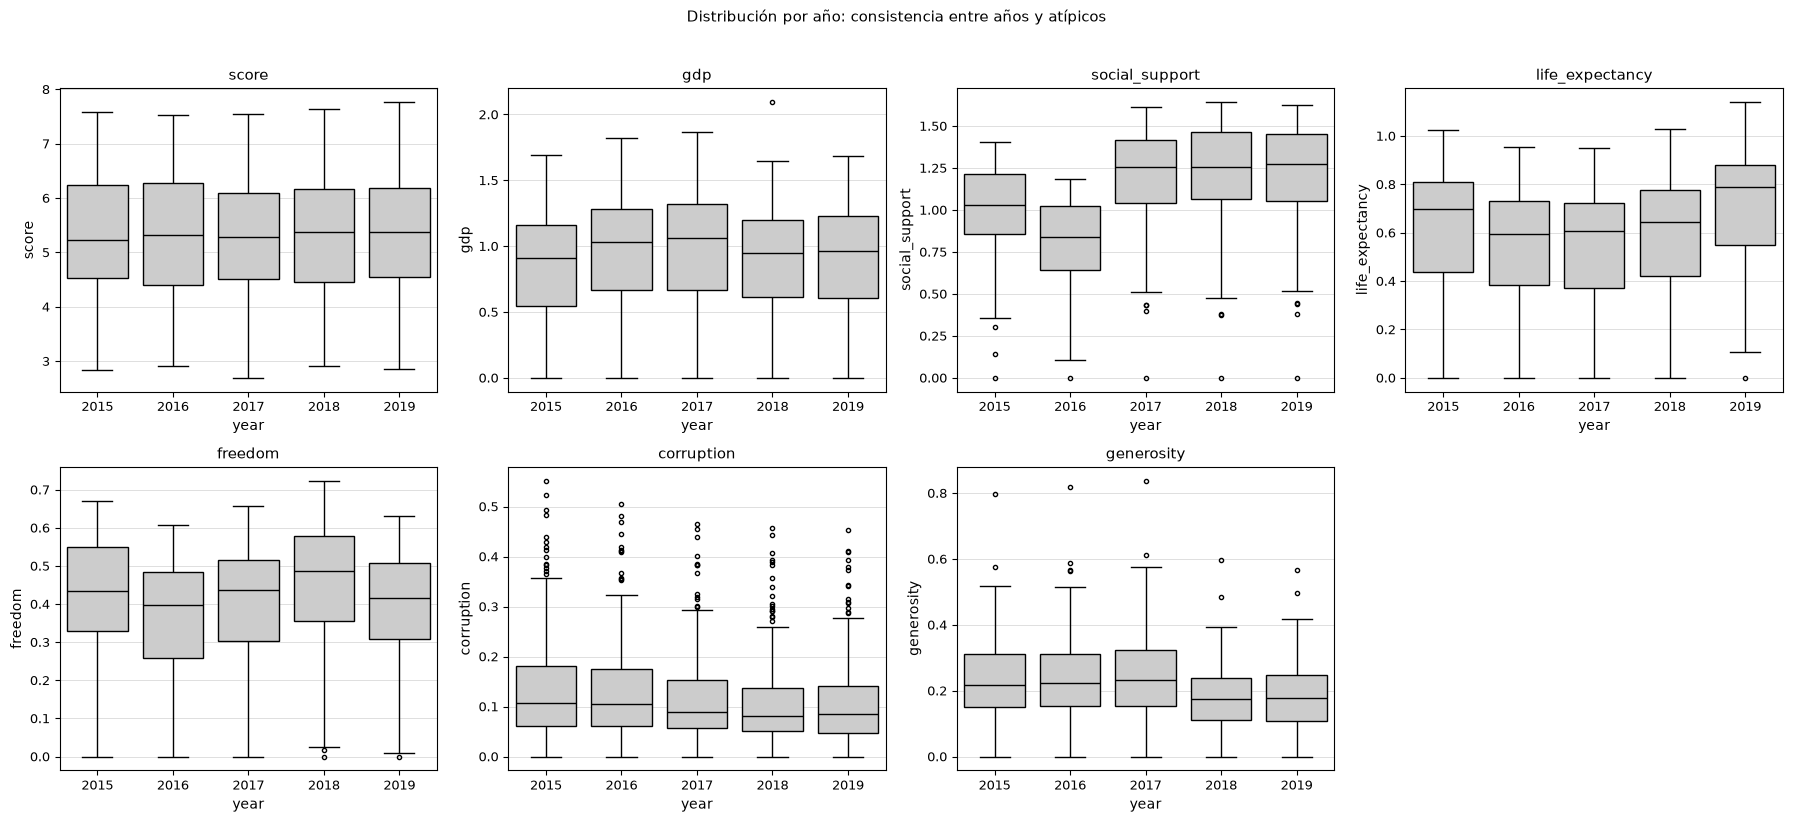

In [24]:
def mascara_atipicos(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

mask_out = pd.DataFrame({v: mascara_atipicos(df[v]) for v in vars_num})
tabla_out = pd.DataFrame({"atipicos": mask_out.sum(),
                          "porcentaje": (mask_out.mean() * 100).round(2)})
display(tabla_out)
reg_limpieza("Filas con algún atípico IQR en predictoras (conservadas)", mask_out[pred].any(axis=1).sum(),
             "valores plausibles; no se eliminan")

# Gráfica 2: distribución por año
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, v in zip(axes.flat, vars_num):
    sns.boxplot(data=df, x="year", y=v, ax=ax, color="0.8", linecolor="black",
                fliersize=3, linewidth=1)
    ax.set_title(v)
axes.flat[-1].axis("off")
plt.suptitle("Distribución por año: consistencia entre años y atípicos", y=1.02)
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/02_boxplots_por_anio.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.10 Cambios de escala entre años
Se compara la media de cada variable por año. Si el `score` medio es estable pero una predictora cambia de nivel de un año a otro, la medición o la escala pudo cambiar. Para separar un cambio de nivel de un cambio en el orden de los países, se comparan los mismos países entre años consecutivos:

- `dif_media`: cambio promedio del valor de un país entre un año y el siguiente. Un valor grande indica un desplazamiento de nivel.
- `corr`: correlación entre los valores de los mismos países en los dos años. Un valor alto indica que el orden relativo de los países se mantiene.

Un desplazamiento de nivel con correlación alta es coherente con un cambio de escala, no con un cambio en la realidad medida.

In [25]:
media_anio = df.groupby("year")[vars_num].mean().round(3)
display(media_anio)

def cambio_pareado(var):
    piv = df.pivot_table(index="country", columns="year", values=var)
    filas = {}
    for a, b in zip(YEARS[:-1], YEARS[1:]):
        par = piv[[a, b]].dropna()
        filas[f"{a}->{b}"] = {"paises_comparados": len(par),
                              "dif_media": round((par[b] - par[a]).mean(), 3),
                              "corr": round(par[a].corr(par[b]), 3)}
    return pd.DataFrame(filas).T

cambio = pd.concat({v: cambio_pareado(v) for v in vars_num})
display(cambio)

salto = cambio.loc[("social_support", "2016->2017"), "dif_media"]
print("Salto medio de social_support entre 2016 y 2017 (mismo nombre 'Family'):", salto)

,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.143,0.237
2016,5.382,0.954,0.794,0.558,0.371,0.138,0.243
2017,5.354,0.985,1.189,0.551,0.409,0.123,0.247
2018,5.376,0.891,1.213,0.597,0.455,0.112,0.181
2019,5.407,0.905,1.209,0.725,0.393,0.111,0.185


paises_comparados  dif_media   corr
score           2015->2016              152.0     -0.010  0.983
                2016->2017              152.0      0.007  0.988
                2017->2018              155.0      0.027  0.986
                2018->2019              153.0      0.040  0.984
gdp             2015->2016              152.0      0.102  0.998
                2016->2017              152.0      0.038  0.999
                2017->2018              155.0     -0.092  0.987
                2018->2019              153.0      0.019  0.990
social_support  2015->2016              152.0     -0.198  0.981
                2016->2017              152.0      0.404  0.983
                2017->2018              155.0      0.025  0.975
                2018->2019              153.0     -0.000  0.977
life_expectancy 2015->2016              152.0     -0.082  0.981
                2016->2017              152.0      0.001  0.998
                2017->2018              155.0      0.047  0.992
                2018->2019              153.0      0.131  0.987
freedom         2015->2016              152.0     -0.060  0.950
                2016->2017              152.0      0.040  0.977
                2017->2018              155.0      0.045  0.942
                2018->2019              153.0     -0.065  0.929
corruption      2015->2016              152.0     -0.005  0.988
                2016->2017              152.0     -0.012  0.993
                2017->2018              154.0     -0.010  0.903
                2018->2019              152.0     -0.003  0.952
generosity      2015->2016              152.0      0.005  0.976
                2016->2017              152.0      0.006  0.985
                2017->2018              155.0     -0.066  0.963
                2018->2019              153.0      0.002  0.969

Salto medio de social_support entre 2016 y 2017 (mismo nombre 'Family'): 0.404


## 5. Exploración de relaciones entre variables

In [26]:
print("Estadísticas descriptivas:")
display(df[vars_num + ["rank"]].describe().round(3))
print("Países únicos:", df["country"].nunique(), "| Años:", [int(y) for y in sorted(df["year"].unique())])
print("\nFilas por región:")
display(df["region"].value_counts().rename("filas").to_frame())

Estadísticas descriptivas:


,score,gdp,social_support,life_expectancy,freedom,corruption,generosity,rank
count,782.000,782.000,782.000,782.000,782.000,781.000,782.000,782.000
mean,5.379,0.916,1.078,0.612,0.411,0.125,0.219,78.698
std,1.127,0.407,0.330,0.248,0.153,0.106,0.122,45.182
min,2.693,0.000,0.000,0.000,0.000,0.000,0.000,1.000
25%,4.510,0.606,0.869,0.440,0.310,0.054,0.130,40.000
50%,5.322,0.982,1.125,0.647,0.431,0.091,0.202,79.000
75%,6.190,1.236,1.327,0.808,0.531,0.156,0.279,118.000
max,7.769,2.096,1.644,1.141,0.724,0.552,0.838,158.000


Países únicos: 164 | Años: [2015, 2016, 2017, 2018, 2019]

Filas por región:


,filas
region,
Sub-Saharan Africa,196
Central and Eastern Europe,145
Latin America and Caribbean,111
Western Europe,105
Middle East and Northern Africa,96
Southeastern Asia,44
Southern Asia,35
Eastern Asia,30
Australia and New Zealand,10


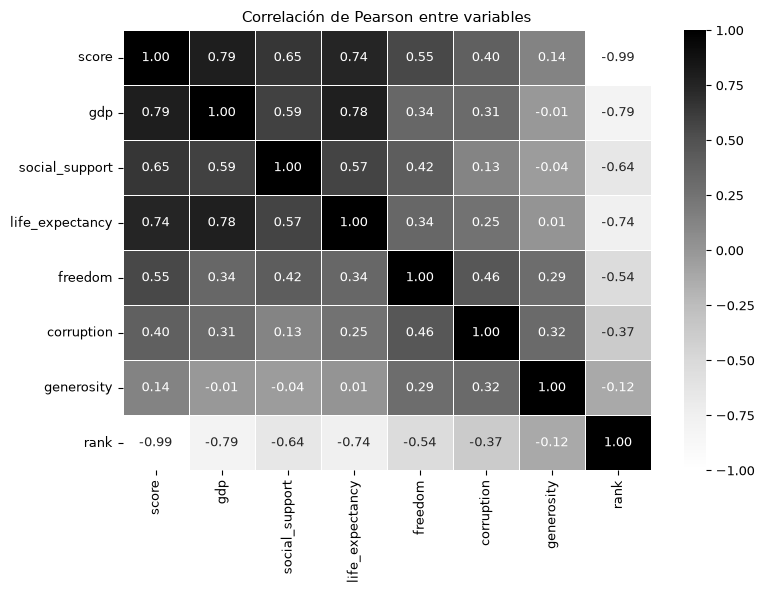

Correlación con score:
gdp                0.789
life_expectancy    0.742
social_support     0.649
freedom            0.551
corruption         0.398
generosity         0.138
rank              -0.992

Pares de predictoras más correlacionados (valor absoluto):
gdp             life_expectancy    0.784
                social_support     0.586
social_support  life_expectancy    0.573
freedom         corruption         0.460
social_support  freedom            0.420


In [27]:
# Gráfica 3: matriz de correlación (incluye rank para justificar su exclusión)
corr = df[vars_num + ["rank"]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greys", vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", ax=ax)
ax.set_title("Correlación de Pearson entre variables")
ax.grid(False)
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/03_correlaciones.png", dpi=150)
plt.show()

corr_score = corr["score"].drop("score").sort_values(ascending=False).round(3)
print("Correlación con score:")
print(corr_score.to_string())

# Multicolinealidad entre predictoras
cp = corr.loc[pred, pred].abs().where(np.triu(np.ones((len(pred), len(pred))), 1).astype(bool)).stack()
print("\nPares de predictoras más correlacionados (valor absoluto):")
print(cp.sort_values(ascending=False).head(5).round(3).to_string())

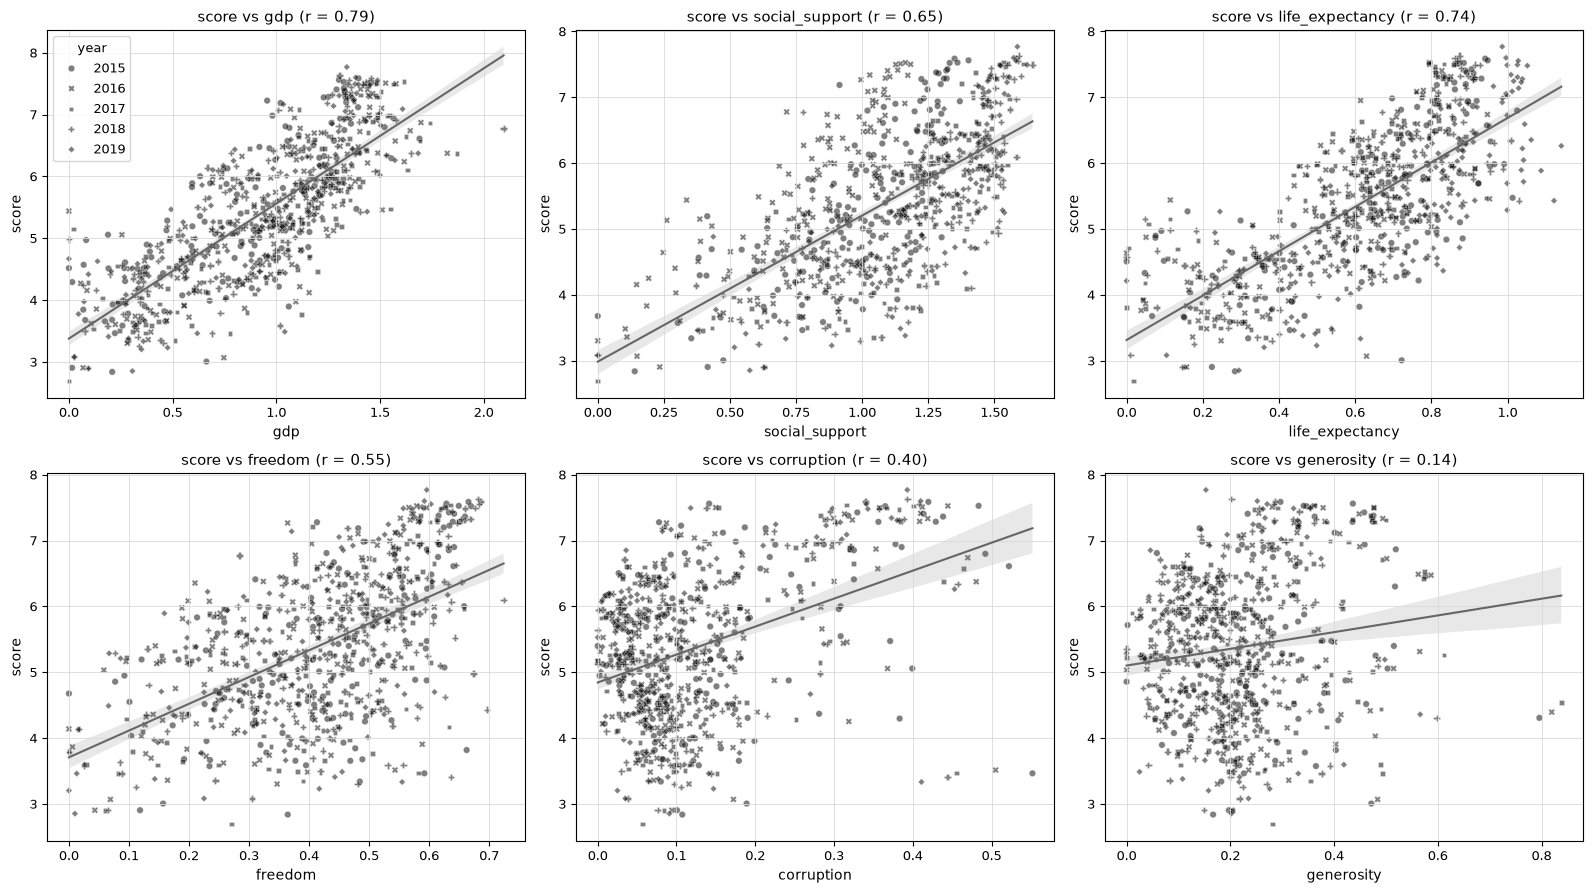

In [28]:
# Gráfica 4: relación de cada predictora con score
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, v in zip(axes.flat, pred):
    sns.scatterplot(data=df, x=v, y="score", style="year", color="black", alpha=.5, s=22,
                    ax=ax, legend=(v == "gdp"))
    sns.regplot(data=df, x=v, y="score", scatter=False, color="0.4",
                line_kws={"linewidth": 1.5}, ax=ax)
    ax.set_title(f"score vs {v} (r = {corr.loc['score', v]:.2f})")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/04_score_vs_variables.png", dpi=150)
plt.show()

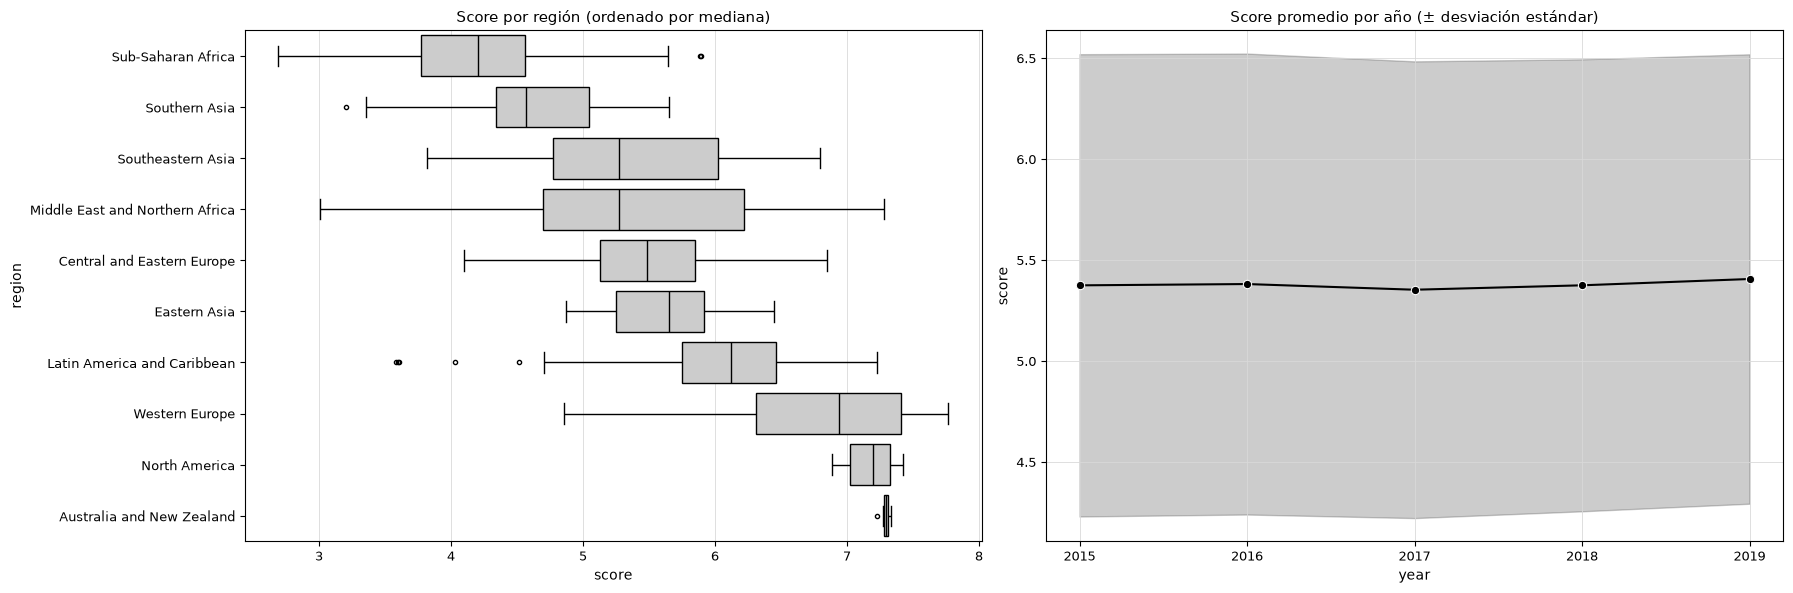

Mediana de score por región:
region
Australia and New Zealand          7.296
North America                      7.198
Western Europe                     6.937
Latin America and Caribbean        6.125
Eastern Asia                       5.655
Central and Eastern Europe         5.488
Middle East and Northern Africa    5.274
Southeastern Asia                  5.271
Southern Asia                      4.565
Sub-Saharan Africa                 4.206


In [29]:
# Gráfica 5: score por región y por año
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
orden = df.groupby("region")["score"].median().sort_values().index
sns.boxplot(data=df, y="region", x="score", order=orden, ax=axes[0], color="0.8",
            linecolor="black", fliersize=3, linewidth=1)
axes[0].set_title("Score por región (ordenado por mediana)")

sns.lineplot(data=df, x="year", y="score", estimator="mean", errorbar="sd",
             marker="o", color="black", ax=axes[1])
axes[1].set_xticks(YEARS)
axes[1].set_title("Score promedio por año (± desviación estándar)")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/05_score_region_anio.png", dpi=150)
plt.show()

med_region = df.groupby("region")["score"].median().sort_values(ascending=False).round(3)
print("Mediana de score por región:")
print(med_region.to_string())

In [30]:
# Estabilidad del score de cada país en el tiempo (condiciona la estrategia de partición)
por_pais = df.groupby("country")["score"].agg(["mean", "std", "count"])
std_dentro = por_pais["std"].mean()
std_total = df["score"].std()
print("Desviación estándar media dentro de cada país:", round(std_dentro, 3))
print("Desviación estándar de todos los registros:   ", round(std_total, 3))
print("Cociente total / dentro:", round(std_total / std_dentro, 1))
print("\nPaíses más estables:")
display(por_pais.sort_values("std").head(3).round(3))
print("Países más variables:")
display(por_pais.sort_values("std").tail(3).round(3))

Desviación estándar media dentro de cada país: 0.188
Desviación estándar de todos los registros:    1.127
Cociente total / dentro: 6.0

Países más estables:


,mean,std,count
country,,,
Somaliland Region,5.057,0.0,2
Suriname,6.269,0.0,2
Belize,5.956,0.0,3


Países más variables:


,mean,std,count
country,,,
Gambia,4.516,NaN,1
Oman,6.853,NaN,1
Puerto Rico,7.039,NaN,1


## 6. Embudo de datos

Consolida lo que **llega** (mensajes de Kafka), lo que se **procesa** (filas y columnas por etapa) y lo que se **limpia** (filas afectadas por cada acción). El dataset limpio se guarda como entrada del notebook de modelado.

In [31]:
# Dataset limpio final
cols_finales = ["year", "country", "region", "rank", "score"] + pred
df = df[cols_finales]
df.to_csv(RUTA_CLEAN, index=False)

filas_completas = int((~df[["region"] + pred].isna().any(axis=1)).sum())
registrar("8. Dataset limpio (entrada de modelado)", len(df), df.shape[1], df["country"].nunique(),
          "%d filas completas, %d con nulo pendiente de imputación" % (filas_completas, len(df) - filas_completas))

# Verificación de integridad contra el archivo guardado
chk = pd.read_csv(RUTA_CLEAN)
assert chk.shape == df.shape
assert not chk.duplicated(["year", "country"]).any()
print("Dataset limpio guardado:", RUTA_CLEAN, chk.shape)

# Tablas del embudo
tabla_embudo = pd.DataFrame(embudo)
tabla_limpieza = pd.DataFrame(limpieza)
display(tabla_embudo)
display(tabla_limpieza)

tabla_embudo.to_csv(f"{DIR_TAB}/embudo_eda.csv", index=False)
tabla_limpieza.to_csv(f"{DIR_TAB}/limpieza_eda.csv", index=False)
mapa_df.sort_values(["unificada", "original"]).to_csv(f"{DIR_TAB}/mapa_columnas.csv", index=False)
pd.DataFrame({"columna_descartada": descartadas}).to_csv(f"{DIR_TAB}/columnas_descartadas.csv", index=False)

Dataset limpio guardado: ../data/clean_records.csv (782, 11)


,etapa,filas,columnas,paises_unicos,nota
0,1. Mensajes disponibles en el tópico,782,NaN,NaN,consulta en vivo a Kafka
1,2. Mensajes consumidos y almacenados,782,35.0,170.0,raw_records.csv (incluye 5 columnas de metadatos)
2,1. Mensajes disponibles en el tópico,782,NaN,NaN,consulta en vivo a Kafka
3,2. Mensajes consumidos y almacenados,782,35.0,170.0,raw_records.csv (incluye 5 columnas de metadatos)
4,3. Sin duplicados por record_id,782,35.0,170.0,duplicados detectados: 0
5,4. Esquema unificado (formato largo),782,11.0,170.0,10 columnas comunes + year; 7 columnas origina...
6,5. Nombres de país unificados,782,11.0,164.0,12 filas renombradas
7,6. Unicidad país-año verificada,782,11.0,164.0,0 duplicados eliminados
8,7. Objetivo (score) válido,782,11.0,164.0,0 filas sin score
9,8. Dataset limpio (entrada de modelado),782,11.0,164.0,"781 filas completas, 1 con nulo pendiente de i..."


,accion,filas_afectadas,decision
0,Espacios sobrantes en nombres de país,0,strip aplicado
1,Nombres de país unificados,12,6 nombres alternativos mapeados al nombre usad...
2,Duplicados país-año eliminados,0,se conserva la primera aparición
3,Filas sin variable objetivo eliminadas,0,no se pueden usar para entrenar
4,Región recuperada por cruce con 2015-2016,466,supone que el país no cambia de región
5,Región asignada manualmente,1,países sin región en 2015-2016: ['Gambia']
6,Nulos en predictoras detectados (imputación pe...,1,"imputación por mediana, ajustada solo con train"
7,Filas con algún cero exacto en predictoras (co...,30,no se confirma si es dato faltante; se documen...
8,Filas con algún atípico IQR en predictoras (co...,91,valores plausibles; no se eliminan


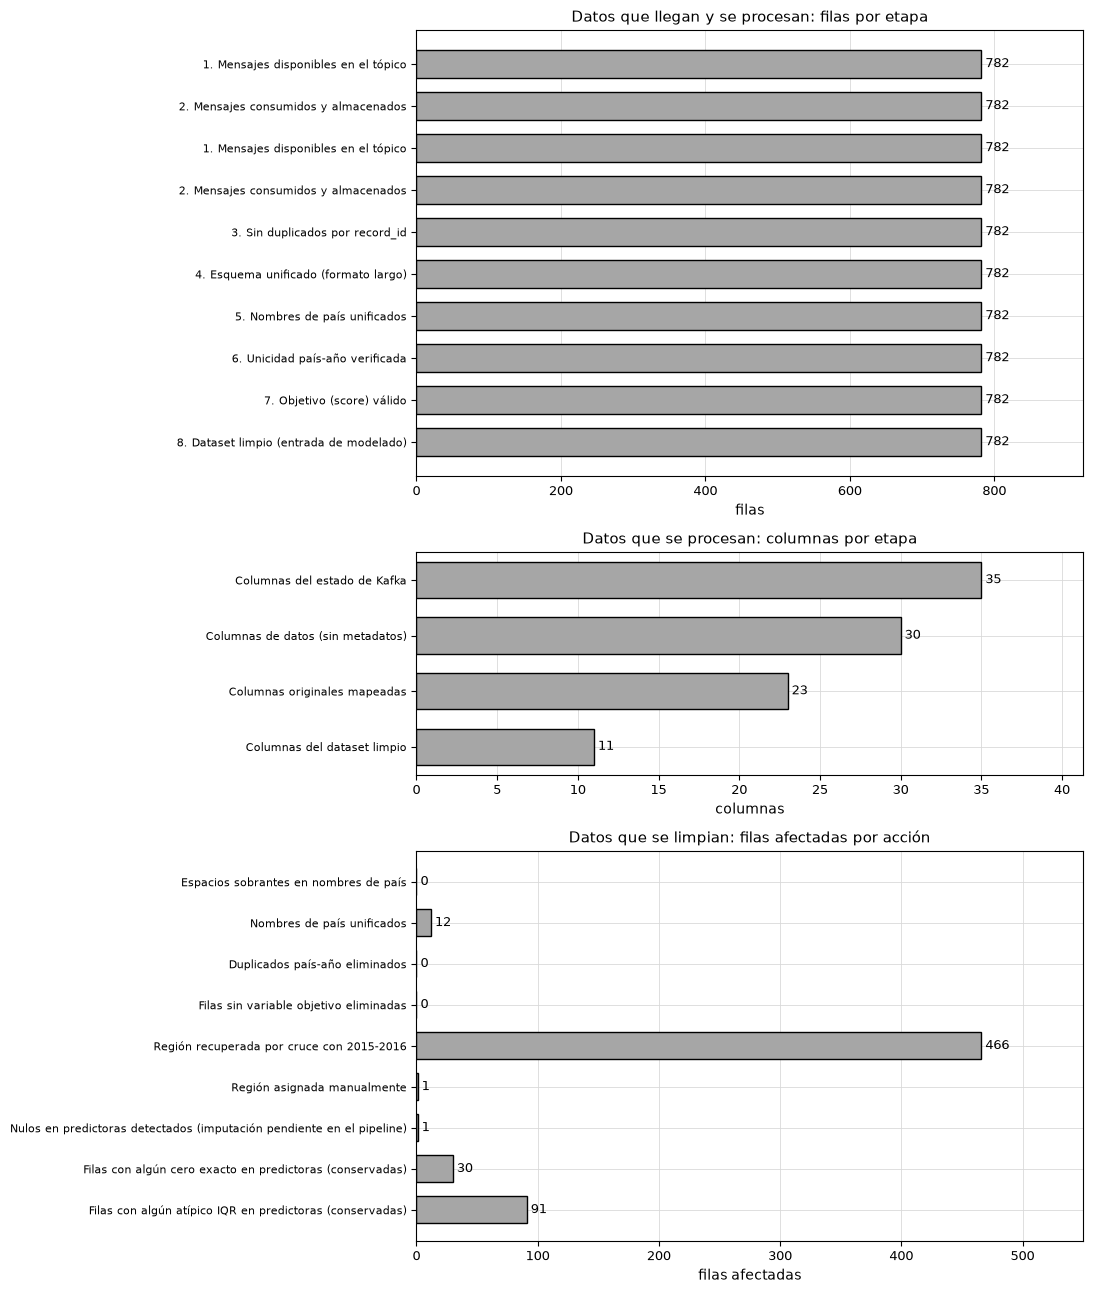

Columnas originales descartadas: 7
['Dystopia Residual', 'Dystopia.Residual', 'Lower Confidence Interval', 'Standard Error', 'Upper Confidence Interval', 'Whisker.high', 'Whisker.low']


In [32]:
# Gráfica 6: embudo (filas por etapa, columnas por etapa, filas afectadas por limpieza)
def barras(ax, etiquetas, valores, titulo, xlabel):
    y = np.arange(len(etiquetas))[::-1]
    ax.set_axisbelow(True)
    ax.barh(y, valores, color="0.65", edgecolor="black", height=0.65)
    for yi, v in zip(y, valores):
        ax.text(v, yi, f" {int(v)}", va="center", fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlim(0, max(valores) * 1.18 if len(valores) and max(valores) > 0 else 1)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)

et_filas = tabla_embudo["etapa"].tolist()
v_filas = tabla_embudo["filas"].tolist()

n_cols_kafka = df_raw.shape[1]
n_cols_datos = len(cols_datos)
n_cols_mapeadas = len([c for c in todas if c in mapa])
n_cols_final = len(cols_finales)
et_cols = ["Columnas del estado de Kafka", "Columnas de datos (sin metadatos)",
           "Columnas originales mapeadas", "Columnas del dataset limpio"]
v_cols = [n_cols_kafka, n_cols_datos, n_cols_mapeadas, n_cols_final]

et_lim = tabla_limpieza["accion"].tolist()
v_lim = tabla_limpieza["filas_afectadas"].tolist()

fig, axes = plt.subplots(3, 1, figsize=(11, 13), gridspec_kw={"height_ratios": [8, 4, 7]})
barras(axes[0], et_filas, v_filas, "Datos que llegan y se procesan: filas por etapa", "filas")
barras(axes[1], et_cols, v_cols, "Datos que se procesan: columnas por etapa", "columnas")
barras(axes[2], et_lim, v_lim, "Datos que se limpian: filas afectadas por acción", "filas afectadas")
plt.tight_layout()
plt.savefig(f"{DIR_FIG}/06_embudo_datos.png", dpi=150)
plt.show()

print("Columnas originales descartadas:", len(descartadas))
print(descartadas)

## 7. Hallazgos, decisiones y limitaciones

El resumen de hallazgos se genera con los valores calculados en este notebook, para que los números coincidan con las salidas.

In [33]:
fila = lambda k: tabla_embudo.loc[tabla_embudo["etapa"].str.startswith(k)].iloc[0]
lim = lambda txt: int(tabla_limpieza.loc[tabla_limpieza["accion"].str.startswith(txt), "filas_afectadas"].sum())

print("RESUMEN DE HALLAZGOS")
print("-" * 70)
print(f"1. Extracción: {int(fila('1.')['filas'])} mensajes en el tópico, "
      f"{int(fila('2.')['filas'])} consumidos, {dup_id} duplicados por record_id.")
print(f"2. Esquemas: {len(todas)} nombres de columna originales en 5 archivos; "
      f"solo {sorted(comunes)} coincide en los 5 años por nombre exacto.")
print(f"3. Integración: {len(df)} filas y {df.shape[1]} columnas en formato largo; "
      f"{len(descartadas)} columnas originales descartadas por no existir en los 5 años.")
print(f"4. Países: {int(fila('4.')['paises_unicos'])} nombres distintos tras integrar, "
      f"{df['country'].nunique()} tras unificar ({lim('Nombres de país')} filas renombradas). "
      f"{int((presentes < 5).sum())} países no aparecen en los 5 años.")
print(f"5. Región: {nulos_region_inicial} filas sin región (2017-2019); "
      f"{lim('Región recuperada')} recuperadas por cruce y {lim('Región asignada')} asignadas manualmente.")
print(f"6. Nulos en predictoras: {len(filas_con_nulos)} fila(s); imputación diferida al pipeline.")
print(f"7. Ceros exactos en predictoras: {int(mask_cero.sum())} filas conservadas (causa no confirmada).")
print(f"8. Atípicos IQR: " + ", ".join(f"{v} {int(n)}" for v, n in tabla_out['atipicos'].items() if n > 0)
      + "; conservados.")
print(f"9. Escala: score medio entre {media_anio['score'].min():.2f} y {media_anio['score'].max():.2f} (estable); "
      f"social_support pasa de {media_anio.loc[2016, 'social_support']:.2f} (2016) a "
      f"{media_anio.loc[2017, 'social_support']:.2f} (2017).")
print("10. Correlación con score: " + ", ".join(f"{k} {v:.2f}" for k, v in corr_score.items()) + ".")
print(f"11. rank: correlación {corr_score['rank']:.2f} con score; se excluye por fuga de datos.")
print(f"12. Estabilidad: desviación dentro de cada país {std_dentro:.2f} frente a {std_total:.2f} total; "
      f"el split de entrenamiento y prueba debe hacerse por país.")
print(f"13. Regiones con mayor mediana de score: {', '.join(med_region.index[:3])}; "
      f"con menor mediana: {', '.join(med_region.index[-3:])}.")

RESUMEN DE HALLAZGOS
----------------------------------------------------------------------
1. Extracción: 782 mensajes en el tópico, 782 consumidos, 0 duplicados por record_id.
2. Esquemas: 30 nombres de columna originales en 5 archivos; solo ['Generosity'] coincide en los 5 años por nombre exacto.
3. Integración: 782 filas y 11 columnas en formato largo; 7 columnas originales descartadas por no existir en los 5 años.
4. Países: 170 nombres distintos tras integrar, 164 tras unificar (12 filas renombradas). 18 países no aparecen en los 5 años.
5. Región: 467 filas sin región (2017-2019); 466 recuperadas por cruce y 1 asignadas manualmente.
6. Nulos en predictoras: 1 fila(s); imputación diferida al pipeline.
7. Ceros exactos en predictoras: 30 filas conservadas (causa no confirmada).
8. Atípicos IQR: social_support 10, corruption 67, generosity 17; conservados.
9. Escala: score medio entre 5.35 y 5.41 (estable); social_support pasa de 0.79 (2016) a 1.19 (2017).
10. Correlación con score

### Decisiones de diseño

| Decisión | Justificación |
|---|---|
| Formato largo (una fila por país-año) | Conserva las 782 observaciones y permite usar `year` como variable |
| Mapa de nombres de columna | Los cinco archivos usan nombres distintos; solo `Generosity` coincide |
| Descartar `Standard Error`, intervalos, `Whisker` y `Dystopia Residual` | No existen en los cinco años |
| Unificar nombres de país | Evita contar un mismo país como dos entidades |
| Recuperar `region` por país | Solo existe en 2015-2016; se asume que un país no cambia de región |
| No imputar nulos aquí | La imputación se ajusta solo con train dentro del `Pipeline` |
| Conservar ceros y atípicos | Su causa no está confirmada o son valores plausibles |
| Excluir `rank` de las predictoras | Se deriva del score; correlación cercana a -1 (fuga de datos) |
| Incluir `year` como variable categórica | Varias predictoras cambian de nivel entre años |
| Partición por país en el modelado | El score de un país casi no cambia entre años |

### Limitaciones

- Un país aparece hasta 5 veces; las filas no son independientes.
- `Family` (2015-2017) y `Social support` (2018-2019) se tratan como una sola variable, pero la tabla de cambios pareados de la sección 4.10 muestra un desplazamiento de nivel entre años. Falta verificarlo con la documentación oficial.
- Los ceros exactos pueden ser datos faltantes codificados como 0; no se pudo confirmar.
- La región de 2017-2019 es una aproximación basada en 2015-2016.
- Las 5 observaciones por país como máximo y los 782 registros totales limitan la complejidad del modelo que se puede validar.

### Siguiente paso
`02_modelado.ipynb` lee `data/clean_records.csv` y `reports/tables/embudo_eda.csv` y continúa el embudo con la partición, el entrenamiento y la evaluación.